In [ ]:
import pandas as pd

In [ ]:
from google.colab import files
import zipfile
uploaded = files.upload()

with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
    zip_ref.extractall('archive')

Saving archive.zip to archive.zip


In [ ]:
df = pd.read_csv('archive.zip')

In [ ]:
# Display the first few rows of the DataFrame
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,02-10-2012 09:00
1,4516,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,02-10-2012 10:00
2,4767,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 11:00
3,5026,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 12:00
4,4918,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,02-10-2012 13:00


In [ ]:
# Display the shape of the DataFrame
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns")

# Display the data types of each column
print(df.dtypes)

The dataset has 48204 rows and 9 columns
traffic_volume           int64
holiday                 object
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main            object
weather_description     object
date_time               object
dtype: object


In [ ]:
# Check for missing values
missing_values = df.isnull().sum()
print(f"Missing values in each column:\n{missing_values}")

Missing values in each column:
traffic_volume             0
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
dtype: int64


In [ ]:
# Change 'holiday' column into numerical variable
df['holiday'] = df['holiday'].apply(lambda x: 0 if pd.isnull(x) else 1)
print(df['holiday'].value_counts())

holiday
0    48143
1       61
Name: count, dtype: int64


In [ ]:
# Display the first few rows of the DataFrame
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,0,288.28,0.0,0.0,40,Clouds,scattered clouds,02-10-2012 09:00
1,4516,0,289.36,0.0,0.0,75,Clouds,broken clouds,02-10-2012 10:00
2,4767,0,289.58,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 11:00
3,5026,0,290.13,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 12:00
4,4918,0,291.14,0.0,0.0,75,Clouds,broken clouds,02-10-2012 13:00


In [ ]:
# Perform statistical analysis
df.describe()

,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,3259.818355,0.001265,281.205870,0.334264,0.000222,49.362231
std,1986.860670,0.035551,13.338232,44.789133,0.008168,39.015750
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1193.000000,0.000000,272.160000,0.000000,0.000000,1.000000
50%,3380.000000,0.000000,282.450000,0.000000,0.000000,64.000000
75%,4933.000000,0.000000,291.806000,0.000000,0.000000,90.000000
max,7280.000000,1.000000,310.070000,9831.300000,0.510000,100.000000


### Data Visualization

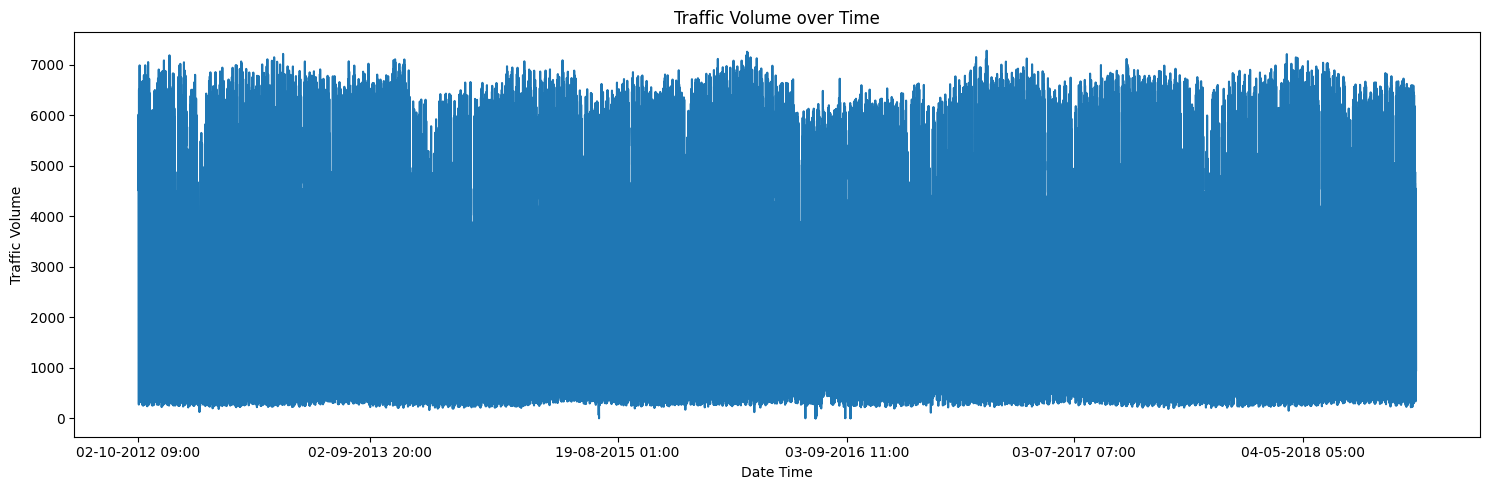

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 5))
plt.plot(df["date_time"], df["traffic_volume"])
plt.xlabel("Date Time")
plt.ylabel("Traffic Volume")
plt.title("Traffic Volume over Time")
plt.xticks(df["date_time"][::8760])
plt.tight_layout()
plt.show()

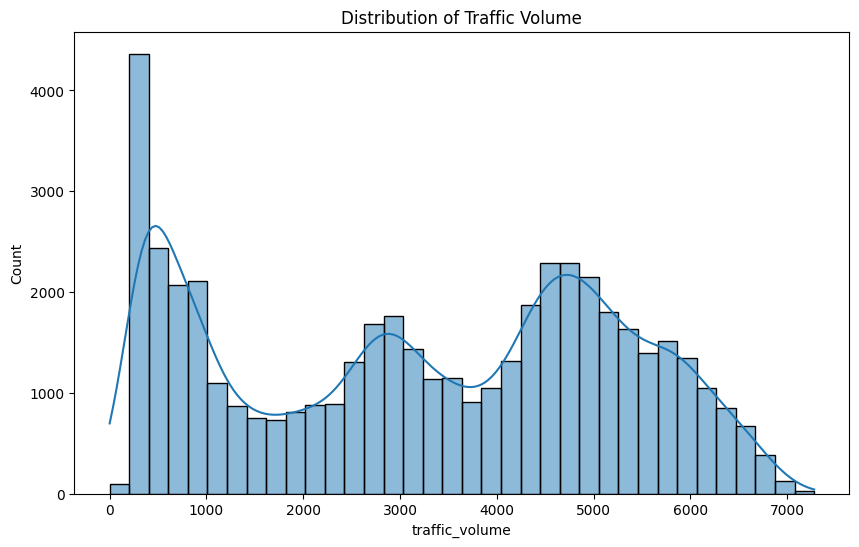

In [ ]:
# Histogram of traffic volume
plt.figure(figsize=(10,6))
sns.histplot(df['traffic_volume'], kde=True)
plt.title('Distribution of Traffic Volume')
plt.show()

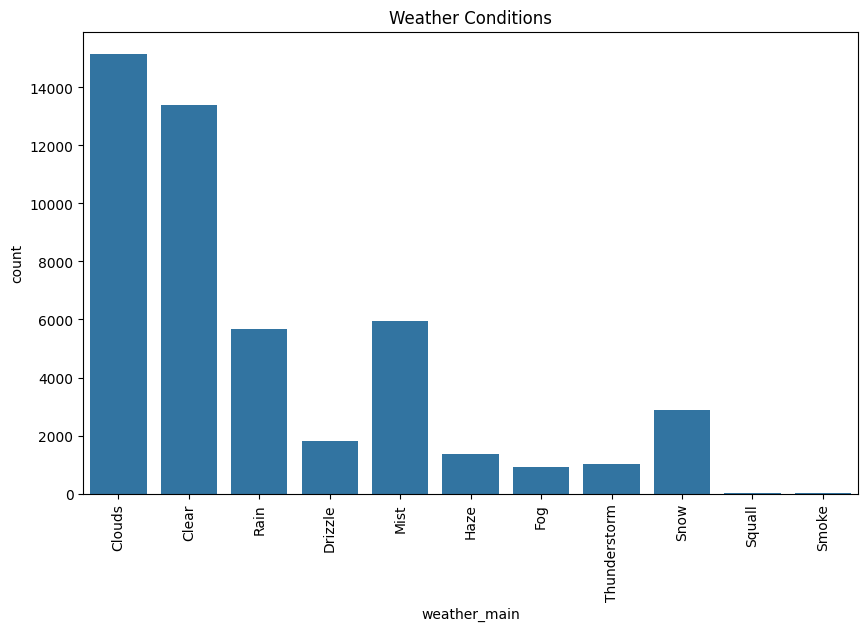

In [ ]:
# Bar plot of weather_main
plt.figure(figsize=(10,6))
sns.countplot(x='weather_main', data=df)
plt.title('Weather Conditions')
plt.xticks(rotation=90)
plt.show()

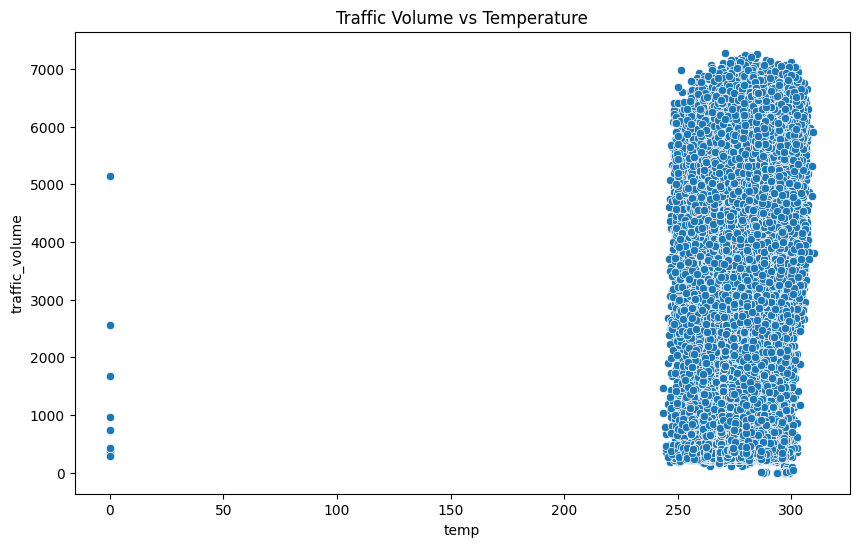

In [ ]:
# Scatter plot of traffic_volume vs temp
plt.figure(figsize=(10,6))
sns.scatterplot(x='temp', y='traffic_volume', data=df)
plt.title('Traffic Volume vs Temperature')
plt.show()

###Feature Extraction

In [ ]:
# Convert to datetime with correct format
df['date_time'] = pd.to_datetime(df['date_time'], format='%d-%m-%Y %H:%M')

# Extract features
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek
df['month'] = df['date_time'].dt.month

In [ ]:
# Drop unimportant features
df = df.drop(columns=['clouds_all', 'weather_description'])

In [ ]:
# Convert 'weather main' into numerical format using one-hot encoding
df = pd.get_dummies(df, columns=['weather_main'], drop_first=True, dtype=int)

In [ ]:
# Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[['temp', 'rain_1h', 'snow_1h']] = scaler.fit_transform(df[['temp', 'rain_1h', 'snow_1h']])

In [ ]:
import numpy as np
# Instead of raw hour, consider cyclical encoding:
df['hour_sin'] = np.sin(2 * np.pi * df['hour']/24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour']/24)

# Instead of day_of_week, consider weekend flag:
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

In [ ]:
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,date_time,hour,day_of_week,month,weather_main_Clouds,...,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm,hour_sin,hour_cos,is_weekend
0,5545,0,0.530370,-0.007463,-0.027228,2012-10-02 09:00:00,9,1,10,1,...,0,0,0,0,0,0,0,7.071068e-01,-0.707107,0
1,4516,0,0.611341,-0.007463,-0.027228,2012-10-02 10:00:00,10,1,10,1,...,0,0,0,0,0,0,0,5.000000e-01,-0.866025,0
2,4767,0,0.627836,-0.007463,-0.027228,2012-10-02 11:00:00,11,1,10,1,...,0,0,0,0,0,0,0,2.588190e-01,-0.965926,0
3,5026,0,0.669071,-0.007463,-0.027228,2012-10-02 12:00:00,12,1,10,1,...,0,0,0,0,0,0,0,1.224647e-16,-1.000000,0
4,4918,0,0.744794,-0.007463,-0.027228,2012-10-02 13:00:00,13,1,10,1,...,0,0,0,0,0,0,0,-2.588190e-01,-0.965926,0


In [ ]:
correlation = df.corr()['traffic_volume'].abs().sort_values(ascending=False)
print(correlation)

selected_features_corr = correlation[correlation > 0.05].index.tolist()

print("\n=== Features with |correlation| > 0.05 ===")
print(selected_features_corr)

traffic_volume               1.000000
hour_cos                     0.764252
hour                         0.352401
hour_sin                     0.244211
is_weekend                   0.218647
day_of_week                  0.149544
temp                         0.130299
weather_main_Clouds          0.122285
weather_main_Mist            0.061734
holiday                      0.042897
weather_main_Fog             0.038868
weather_main_Snow            0.030804
weather_main_Haze            0.020778
weather_main_Thunderstorm    0.019241
weather_main_Rain            0.010676
weather_main_Squall          0.005493
rain_1h                      0.004714
date_time                    0.004449
weather_main_Drizzle         0.003082
month                        0.002533
snow_1h                      0.000733
weather_main_Smoke           0.000227
Name: traffic_volume, dtype: float64

=== Features with |correlation| > 0.05 ===
['traffic_volume', 'hour_cos', 'hour', 'hour_sin', 'is_weekend', 'day_of_week', 'te

###Save Preprocessed Data into New CSV File

In [ ]:
df.to_csv('prediction_traffic.csv', index=False)
print("✅ Preprocessed data saved as 'prediction_traffic.csv'")

✅ Preprocessed data saved as 'prediction_traffic.csv'


###SARIMAX


In [ ]:
pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 116.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 15.4 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Set datetime as index and sort
df.set_index('date_time', inplace=True)
df.sort_index(inplace=True)

Text(0, 0.5, 'Traffic Volume')

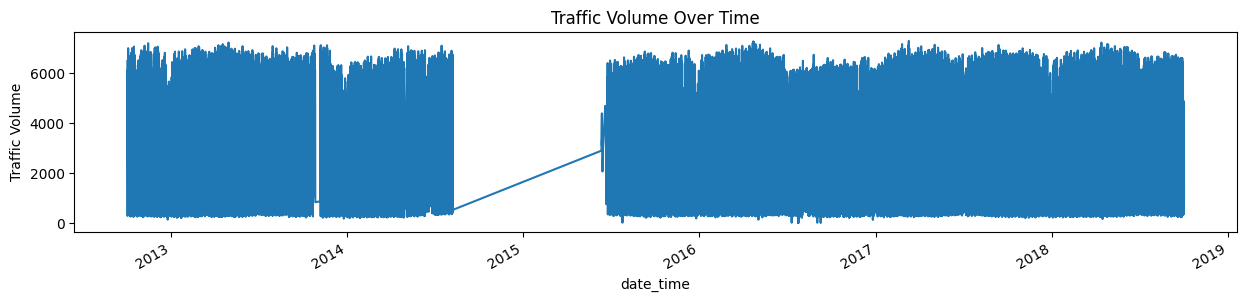

In [ ]:
# Plot the time series
plt.figure(figsize=(15, 10))

plt.subplot(3, 1, 1)
df['traffic_volume'].plot(title='Traffic Volume Over Time')
plt.ylabel('Traffic Volume')

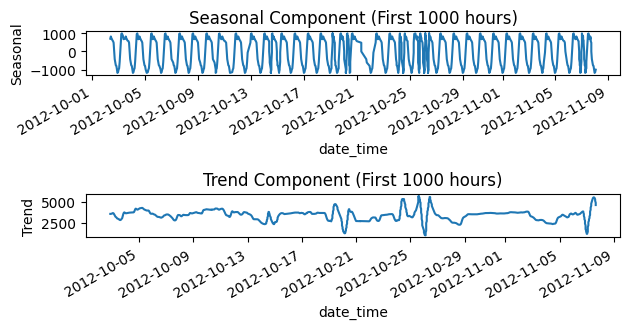

In [ ]:
# Seasonal decomposition to identify patterns
plt.subplot(3, 1, 2)

# Use a subset for decomposition to avoid memory issues
decomposition = seasonal_decompose(df['traffic_volume'].iloc[:1000], period=24)  # 24 hours daily seasonality
decomposition.seasonal.plot(title='Seasonal Component (First 1000 hours)')
plt.ylabel('Seasonal')

plt.subplot(3, 1, 3)
decomposition.trend.plot(title='Trend Component (First 1000 hours)')
plt.ylabel('Trend')

plt.tight_layout()
plt.show()

In [ ]:
def check_stationarity(timeseries):
    result = adfuller(timeseries.dropna())
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    print('Critical Values:')
    for key, value in result[4].items():
        print(f'\t{key}: {value}')

    if result[1] <= 0.05:
        print("Series is stationary")
    else:
        print("Series is not stationary")

print("Stationarity check for traffic volume:")
check_stationarity(df['traffic_volume'])

Stationarity check for traffic volume:
ADF Statistic: -28.016624319503496
p-value: 0.0
Critical Values:
	1%: -3.4304858041453006
	5%: -2.861600022592497
	10%: -2.5668019480496826
Series is stationary


<Figure size 1000x400 with 0 Axes>

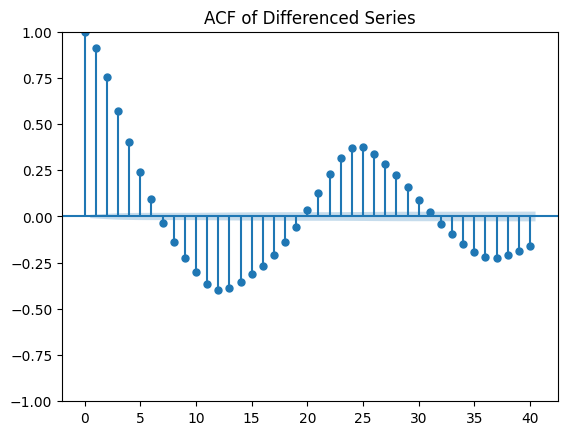

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

diff = df['traffic_volume'].dropna()

plt.figure(figsize=(10, 4))
plot_acf(diff, lags=40)
plt.title('ACF of Differenced Series')
plt.show()

<Figure size 1000x400 with 0 Axes>

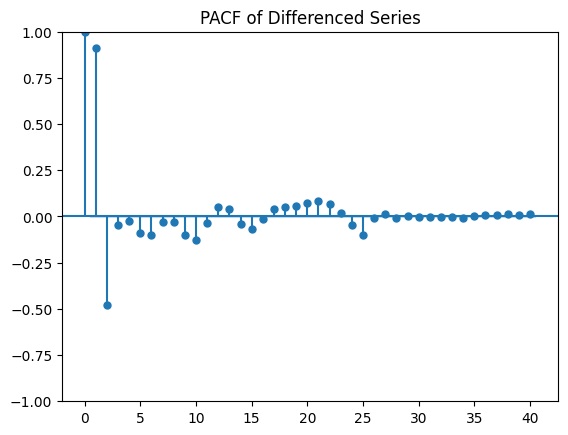

In [ ]:
plt.figure(figsize=(10, 4))
plot_pacf(diff, lags=40, method='ywm')
plt.title('PACF of Differenced Series')
plt.show()

In [ ]:
df['traffic_seasonal'] = df['traffic_volume'].diff(24)
print(f'\n===== After seasonal difference =====')
check_stationarity(df['traffic_seasonal'])


===== After seasonal difference =====
ADF Statistic: -37.91501319459725
p-value: 0.0
Critical Values:
	1%: -3.430485897278917
	5%: -2.8616000637546652
	10%: -2.566801969959114
Series is stationary


<Figure size 1000x400 with 0 Axes>

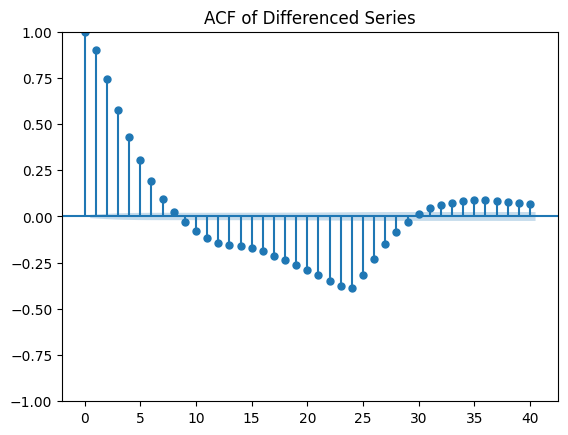

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

diff = df['traffic_volume'].diff(24).dropna()

plt.figure(figsize=(10, 4))
plot_acf(diff, lags=40)
plt.title('ACF of Differenced Series')
plt.show()

<Figure size 1000x400 with 0 Axes>

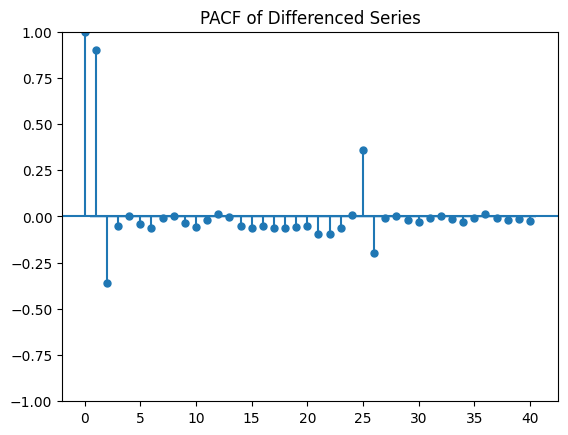

In [ ]:
plt.figure(figsize=(10, 4))
plot_pacf(diff, lags=40, method='ywm')
plt.title('PACF of Differenced Series')
plt.show()

In [ ]:
# Prepare features for SARIMAX
# Select exogenous variables based on your correlation analysis
exog_features = ['hour_cos', 'hour_sin', 'is_weekend']
X = df[exog_features]
y = df['traffic_volume']

In [ ]:
# Use last year to test only
split_date = '2018-01-01'

y_train = y[y.index <= split_date]
y_test  = y[y.index > split_date]

X_train = X[X.index <= split_date]
X_test  = X[X.index > split_date]

In [ ]:
# Model with daily seasonality (24 hours)
model = SARIMAX(y_train,
                exog=X_train,
                order=(1, 0, 0),           # (p, d, q) - non-seasonal parameters
                seasonal_order=(1, 1, 1, 24), # (P, D, Q, s) - seasonal parameters (24 hours)
                enforce_stationarity=False,
                enforce_invertibility=False)

sarimax_result = model.fit(disp=False)
print("SARIMAX model fitted successfully!")
print(sarimax_result.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


SARIMAX model fitted successfully!
                                      SARIMAX Results                                       
Dep. Variable:                       traffic_volume   No. Observations:                40256
Model:             SARIMAX(1, 0, 0)x(1, 1, [1], 24)   Log Likelihood             -318263.045
Date:                              Wed, 24 Dec 2025   AIC                         636540.090
Time:                                      06:18:42   BIC                         636600.303
Sample:                                           0   HQIC                        636559.144
                                            - 40256                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
hour_cos   -2175.8586     12.483   -174.305      0.000   -2200.

In [ ]:
# In-sample fitted values on the training set
sarimax_fitted_train = sarimax_result.fittedvalues

# Out-of-sample forecast for the test period
sarimax_forecast_test = sarimax_result.predict(
    start=len(y_train),
    end=len(y_train) + len(y_test) - 1,
    exog=X_test
)

# Residuals on the training data
residuals_train = y_train - sarimax_fitted_train


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


###XGBoost

In [ ]:
# ----- TRAIN -----
X_train_ml = X_train.copy()
X_train_ml['hour'] = X_train.index.hour
X_train_ml['day_of_week'] = X_train.index.dayofweek
X_train_ml['month'] = X_train.index.month
X_train_ml['sarimax_pred'] = sarimax_fitted_train

y_train_ml = residuals_train

# ----- TEST -----
X_test_ml = X_test.copy()
X_test_ml['hour'] = X_test.index.hour
X_test_ml['day_of_week'] = X_test.index.dayofweek
X_test_ml['month'] = X_test.index.month
X_test_ml['sarimax_pred'] = sarimax_forecast_test


In [ ]:
pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.8/296.8 MB 1.3 MB/s eta 0:00:00


In [ ]:
from xgboost import XGBRegressor
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.01,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

features = ['hour', 'day_of_week', 'month', 'hour_sin', 'hour_cos', 'is_weekend', 'sarimax_pred']
xgb.fit(X_train_ml[features], y_train_ml)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.01, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# XGBoost predicts the residual correction
resid_pred_test = xgb.predict(X_test_ml[features])

# SARIMAX forecast + XGBoost predicted residual
final_hybrid_pred = sarimax_forecast_test + resid_pred_test

###Model Performance

In [ ]:
rmse_sarimax = np.sqrt(mean_squared_error(y_test, sarimax_forecast_test))
rmse_hybrid  = np.sqrt(mean_squared_error(y_test, final_hybrid_pred))

mae_sarimax = mean_absolute_error(y_test, sarimax_forecast_test)
mae_hybrid  = mean_absolute_error(y_test, final_hybrid_pred)

print("RMSE  SARIMAX:", rmse_sarimax)
print("RMSE  Hybrid :", rmse_hybrid)
print("MAE   SARIMAX:", mae_sarimax)
print("MAE   Hybrid :", mae_hybrid)


RMSE  SARIMAX: 1112.9067535598522
RMSE  Hybrid : 1072.1461079216035
MAE   SARIMAX: 879.3423696907062
MAE   Hybrid : 816.6703673334043


In [ ]:
# Calculate metrics
import numpy as np

# Align predictions to match y_test length
y_test_reset = y_test.reset_index(drop=True)
final_hybrid_pred_reset = final_hybrid_pred.reset_index(drop=True)

mae = mean_absolute_error(y_test_reset, final_hybrid_pred_reset)
rmse = np.sqrt(mean_squared_error(y_test_reset, final_hybrid_pred_reset))
r2 = r2_score(y_test_reset, final_hybrid_pred_reset)
mape = np.mean(np.abs((y_test_reset - final_hybrid_pred_reset) / y_test_reset)) * 100

print(f"\n=== Model Performance ===")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"R-squared: {r2:.2f}")


=== Model Performance ===
MAE: 816.67
RMSE: 1072.15
MAPE: 37.73%
R-squared: 0.70


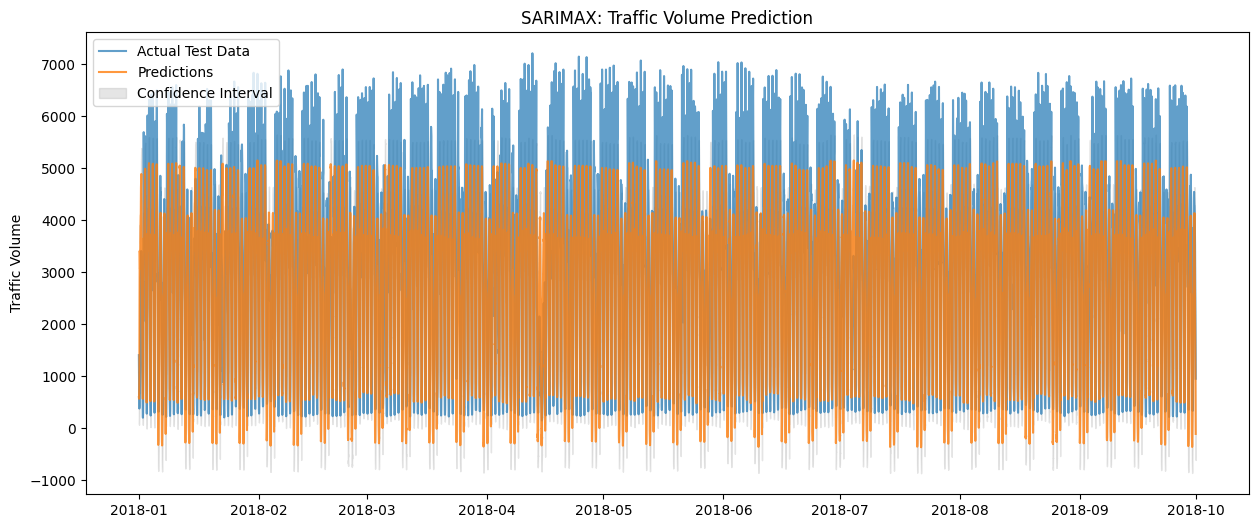

In [ ]:
# Plot results
plt.figure(figsize=(15, 6))

ci_lower = final_hybrid_pred - 500
ci_upper = final_hybrid_pred + 500

plt.plot(y_test.index, y_test, label='Actual Test Data', alpha=0.7)
plt.plot(y_test.index, final_hybrid_pred, label='Predictions', alpha=0.8)
plt.fill_between(y_test.index,
                ci_lower,
                ci_upper,
                alpha=0.2, color='gray', label='Confidence Interval')
plt.title('SARIMAX: Traffic Volume Prediction')
plt.ylabel('Traffic Volume')
plt.legend()

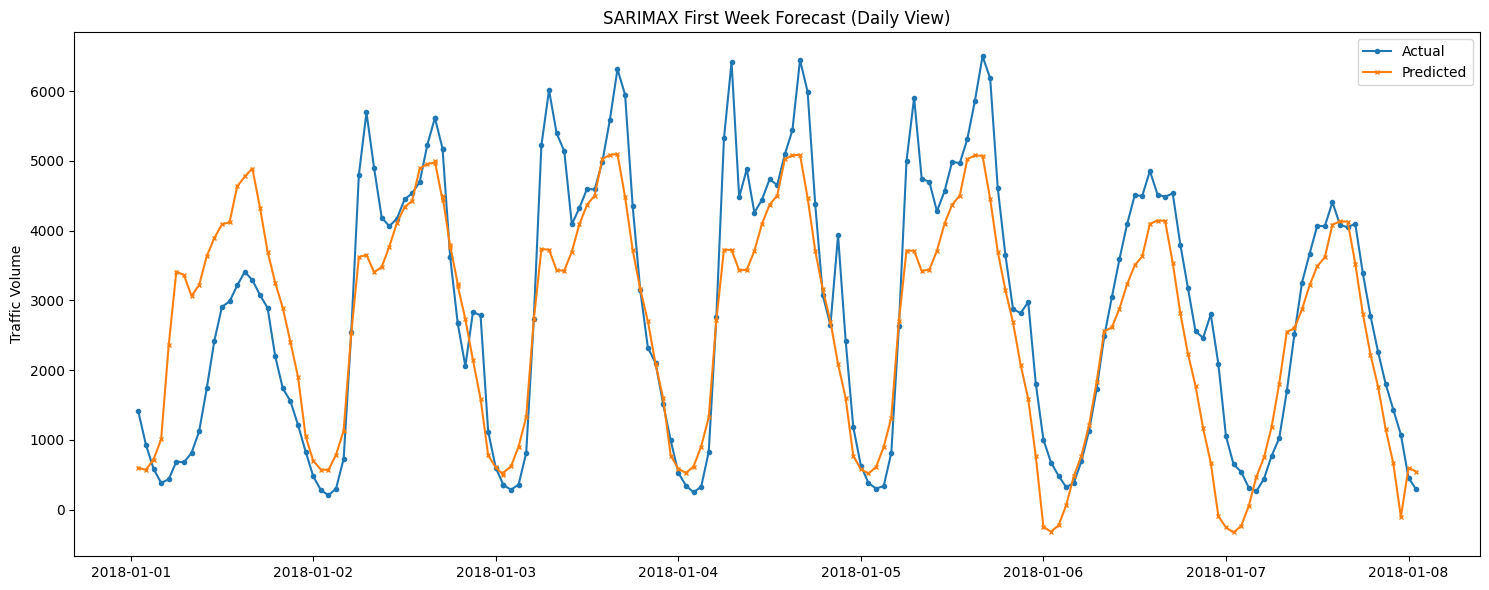

In [ ]:
# Plot 2: Zoom in on test period (first 7 days)
test_start = y_test.index[0]
test_first_week = test_start + pd.Timedelta(days=7)
mask = (y_test.index >= test_start) & (y_test.index <= test_first_week)
plt.figure(figsize=(15,6))
plt.plot(y_test.index[mask], y_test[mask], label='Actual', marker='o', markersize=3)
plt.plot(y_test.index[mask], final_hybrid_pred[mask], label='Predicted', marker='x', markersize=3)
plt.title('SARIMAX First Week Forecast (Daily View)')
plt.ylabel('Traffic Volume')
plt.legend()

plt.tight_layout()
plt.show()

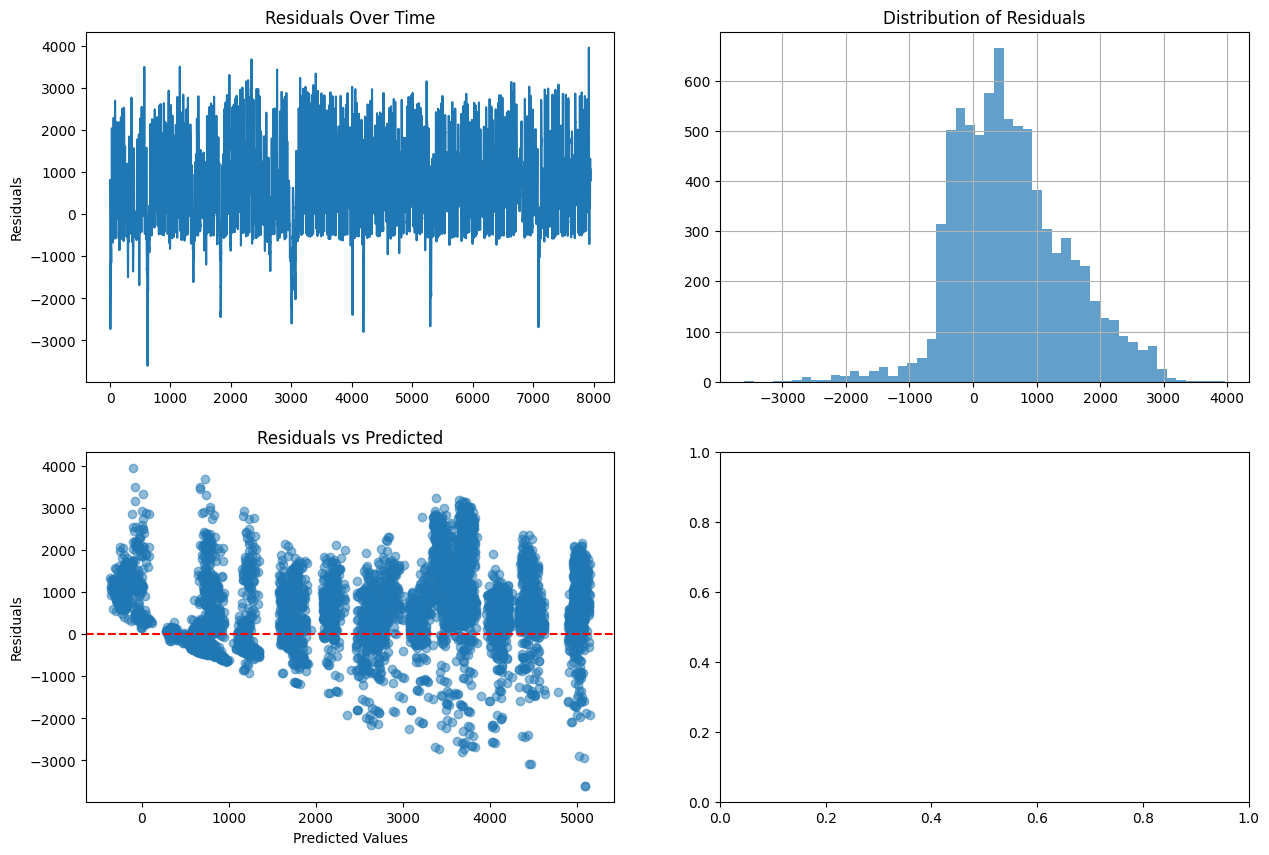

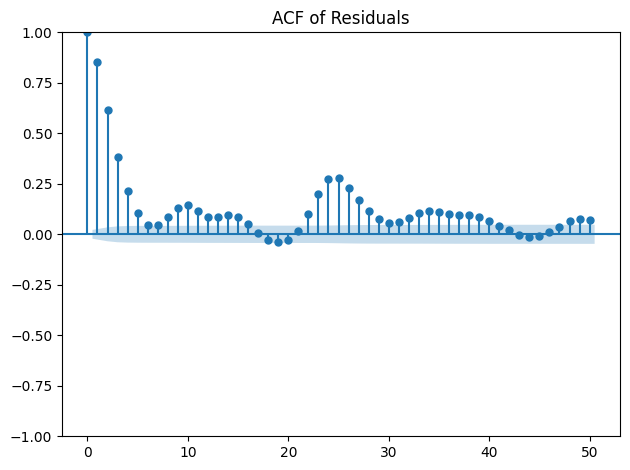

In [ ]:
# Residual analysis
residuals = y_test_reset - final_hybrid_pred_reset

plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
residuals.plot(title='Residuals Over Time')
plt.ylabel('Residuals')

plt.subplot(2, 2, 2)
residuals.hist(bins=50, alpha=0.7)
plt.title('Distribution of Residuals')

plt.subplot(2, 2, 3)
plt.scatter(final_hybrid_pred_reset, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')

plt.subplot(2, 2, 4)
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(residuals, lags=50, alpha=0.05, title='ACF of Residuals')

plt.tight_layout()
plt.show()

###Forecast (1 Year)

In [ ]:
from datetime import datetime, timedelta

# Create future dates for 1 year
future_dates = pd.date_range(start=pd.to_datetime('2018-10-01') + timedelta(hours=1),
                            periods=365*24, freq='h')

def create_future_features(future_dates):
    future_df = pd.DataFrame({'date_time': future_dates})

    # Extract basic time features
    future_df['hour'] = future_df['date_time'].dt.hour
    future_df['day_of_week'] = future_df['date_time'].dt.dayofweek
    future_df['month'] = future_df['date_time'].dt.month

    # Create the same engineered features you used in training
    future_df['hour_sin'] = np.sin(2 * np.pi * future_df['hour']/24)
    future_df['hour_cos'] = np.cos(2 * np.pi * future_df['hour']/24)
    future_df['is_weekend'] = future_df['day_of_week'].isin([5, 6]).astype(int)

    future_df.set_index('date_time', inplace=True)

    return future_df

# Create future features
future_df = create_future_features(future_dates)

In [ ]:
# Prepare SARIMAX exogenous features (only original 3)
future_exog_for_sarimax = future_df[['hour_cos', 'hour_sin', 'is_weekend']]

# SARIMAX forecast
forecast = sarimax_result.get_forecast(steps=365*24, exog=future_exog_for_sarimax)
sarimax_future_pred = forecast.predicted_mean
ci = forecast.conf_int()

# Add SARIMAX predictions as feature for XGBoost
future_df['sarimax_pred'] = sarimax_future_pred.values

# Use full future_df for XGBoost prediction
future_exog_for_xgb = future_df[['hour', 'day_of_week', 'month', 'hour_sin', 'hour_cos', 'is_weekend', 'sarimax_pred']]
xgb_future_pred = xgb.predict(future_exog_for_xgb)

# Final hybrid forecast
final_hybrid_forecast = sarimax_future_pred + xgb_future_pred

# Create results DataFrame
results_df = pd.DataFrame({
    'date': future_dates,
    'predicted_traffic': final_hybrid_forecast,
    'lower_ci': ci.iloc[:, 0] + xgb_future_pred,
    'upper_ci': ci.iloc[:, 1] + xgb_future_pred
})

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


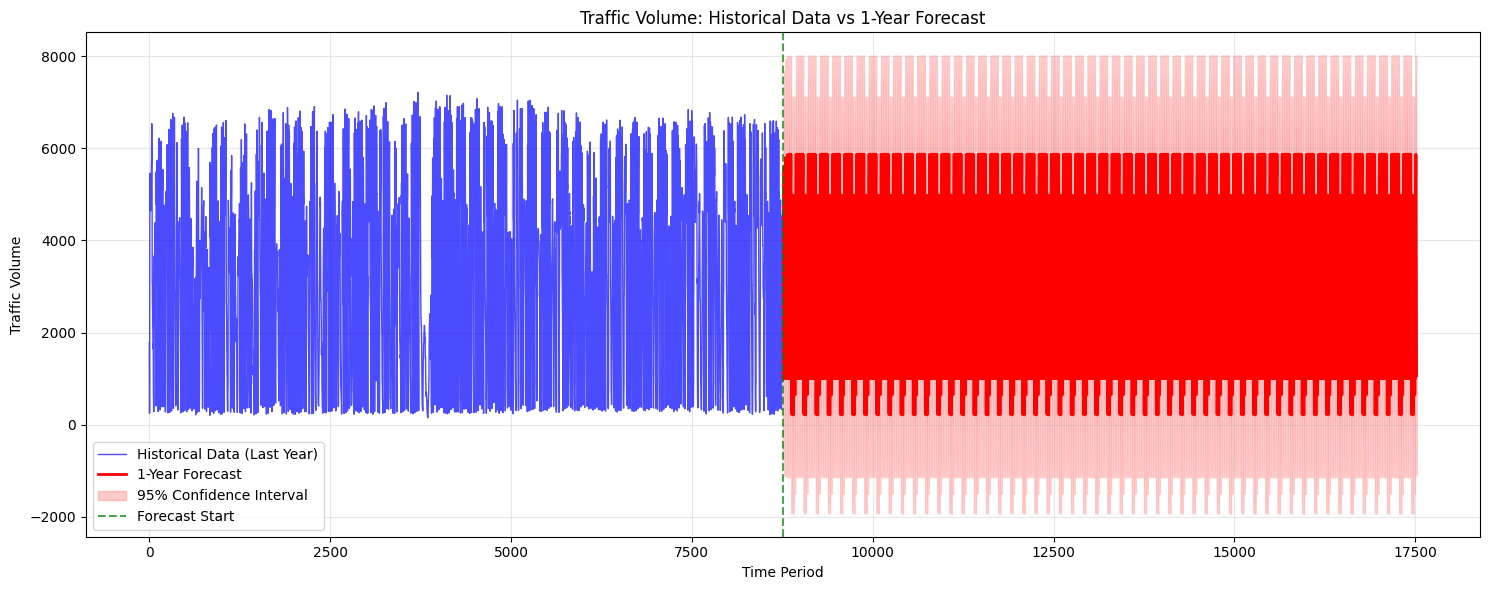

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

# Plot historical data (last year) using index
historical_data = df['traffic_volume'].iloc[-365*24:]

# Create x-axis values (indices)
historical_indices = range(len(historical_data))

plt.plot(historical_indices, historical_data,
         label='Historical Data (Last Year)', color='blue', alpha=0.7, linewidth=1)

# Forecast
forecast_indices = range(len(historical_data), len(historical_data) + len(results_df))

plt.plot(forecast_indices, results_df['predicted_traffic'],
         label='1-Year Forecast', color='red', linewidth=2)

if 'lower_ci' in results_df.columns:
    plt.fill_between(forecast_indices,
                    results_df['lower_ci'],
                    results_df['upper_ci'],
                    color='red', alpha=0.2, label='95% Confidence Interval')

# Add vertical line to show forecast start
plt.axvline(x=len(historical_data), color='green', linestyle='--',
            alpha=0.7, label='Forecast Start')

plt.title('Traffic Volume: Historical Data vs 1-Year Forecast')
plt.xlabel('Time Period')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

###Forecast (1 Week)

In [ ]:
from datetime import datetime, timedelta

# Create future dates for 1 week
future_dates = pd.date_range(start=pd.to_datetime('2018-10-01') + timedelta(hours=1),
                            periods=7*24, freq='h')

def create_future_features(future_dates):
    future_df = pd.DataFrame({'date_time': future_dates})

    # Extract basic time features
    future_df['hour'] = future_df['date_time'].dt.hour
    future_df['day_of_week'] = future_df['date_time'].dt.dayofweek
    future_df['month'] = future_df['date_time'].dt.month

    # Create the same engineered features you used in training
    future_df['hour_sin'] = np.sin(2 * np.pi * future_df['hour']/24)
    future_df['hour_cos'] = np.cos(2 * np.pi * future_df['hour']/24)
    future_df['is_weekend'] = future_df['day_of_week'].isin([5, 6]).astype(int)

    future_df.set_index('date_time', inplace=True)

    return future_df

# Create future features
future_df = create_future_features(future_dates)

In [ ]:
# Prepare SARIMAX exogenous features (only original 3)
future_exog_for_sarimax = future_df[['hour_cos', 'hour_sin', 'is_weekend']]

# SARIMAX forecast
forecast = sarimax_result.get_forecast(steps=7*24, exog=future_exog_for_sarimax)
sarimax_future_pred = forecast.predicted_mean
ci = forecast.conf_int()

# Add SARIMAX predictions as feature for XGBoost
future_df['sarimax_pred'] = sarimax_future_pred.values

# Use full future_df for XGBoost prediction
future_exog_for_xgb = future_df[['hour', 'day_of_week', 'month', 'hour_sin', 'hour_cos', 'is_weekend', 'sarimax_pred']]
xgb_future_pred = xgb.predict(future_exog_for_xgb)

# Final hybrid forecast
final_hybrid_forecast = sarimax_future_pred + xgb_future_pred

# Create results DataFrame
results_df = pd.DataFrame({
    'date': future_dates,
    'predicted_traffic': final_hybrid_forecast,
    'lower_ci': ci.iloc[:, 0] + xgb_future_pred,
    'upper_ci': ci.iloc[:, 1] + xgb_future_pred
})

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


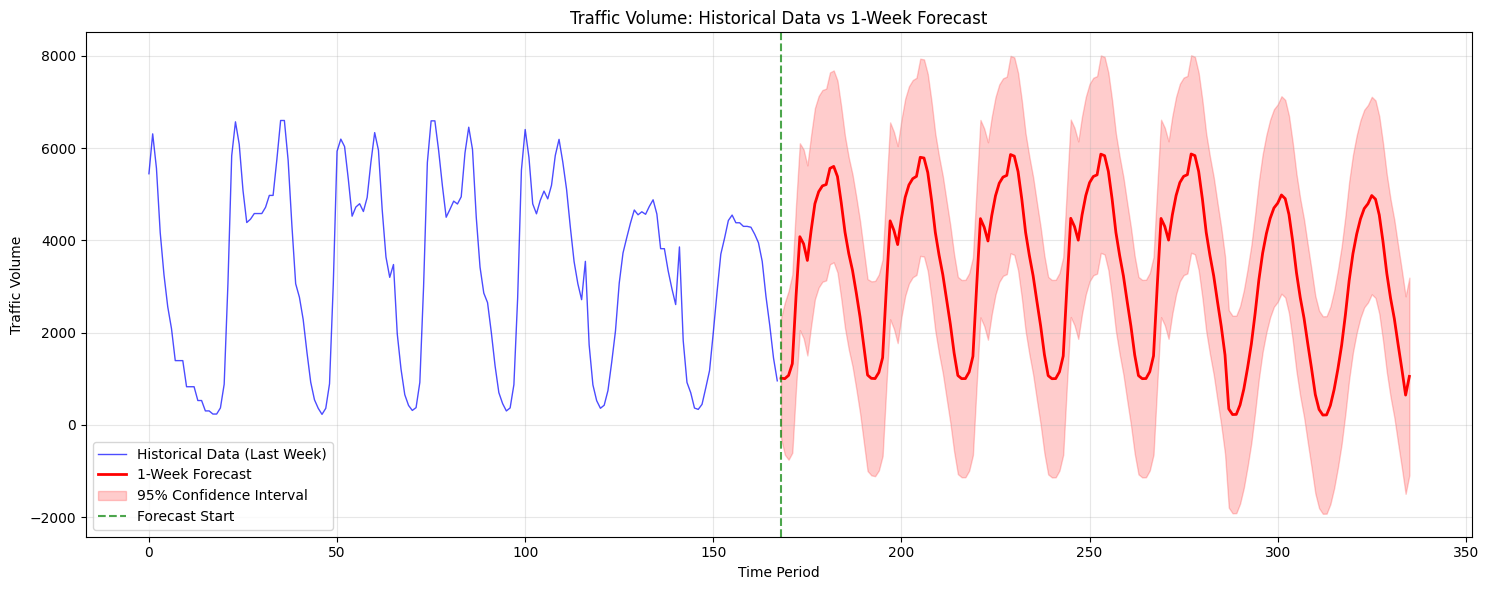

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

# Plot historical data (last week) using index
historical_data = df['traffic_volume'].iloc[-7*24:]  # Last year of data

# Create x-axis values (indices)
historical_indices = range(len(historical_data))

plt.plot(historical_indices, historical_data,
         label='Historical Data (Last Week)', color='blue', alpha=0.7, linewidth=1)

# Forecast
forecast_indices = range(len(historical_data), len(historical_data) + len(results_df))

plt.plot(forecast_indices, results_df['predicted_traffic'],
         label='1-Week Forecast', color='red', linewidth=2)

if 'lower_ci' in results_df.columns:
    plt.fill_between(forecast_indices,
                    results_df['lower_ci'],
                    results_df['upper_ci'],
                    color='red', alpha=0.2, label='95% Confidence Interval')

# Add vertical line to show forecast start
plt.axvline(x=len(historical_data), color='green', linestyle='--',
            alpha=0.7, label='Forecast Start')

plt.title('Traffic Volume: Historical Data vs 1-Week Forecast')
plt.xlabel('Time Period')
plt.ylabel('Traffic Volume')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()